# Лабораторна робота № 3
## Діагностика шкал вимірювання

Курс СК26 «Інтелектуальний аналіз та візуалізація даних»

**Тривалість:** 2 год аудиторно + 3 год самостійно · **Оцінка:** 4 бали
**Файли:** `Ковід_дані_навчальні.xlsx`, `ЛР3_помилковий_аналіз.ipynb`

---

Шкала вимірювання визначає, які операції над змінною взагалі мають сенс.
Комп'ютер цього не знає: він порахує середнє від номера телефону й не поскаржиться.
Знати має вимірювач.

У цій роботі ви складаєте **паспорт восьми змінних** свого варіанта, показуєте на
власних даних, які статистики для них недопустимі, і виправляєте чужий аналіз,
де таких помилок десять.

In [1]:
ПРІЗВИЩЕ_ІМЯ = 'Боднар Денис Васильович'
ГРУПА        = 'ШІ-33'
НОМЕР        = 1       # ваш номер за списком групи (1–30)

assert ПРІЗВИЩЕ_ІМЯ and ГРУПА and НОМЕР, 'Заповніть три поля вище'
assert 1 <= НОМЕР <= 30, 'Номер має бути від 1 до 30'

In [2]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_colwidth', 60)

ВАРІАНТИ = json.load(open('lr3_variants_student.json'))
В = ВАРІАНТИ[НОМЕР - 1]

print('=' * 74)
print(f'ВАРІАНТ {В["варіант"]}   ·   {ПРІЗВИЩЕ_ІМЯ}   ·   {ГРУПА}')
print('=' * 74)
print()
print('Ваші вісім стовпців:')
for i, c in enumerate(В['стовпці'], 1):
    print(f'   {i}. {c}')
print()
print('Ваша пара для аналізу зв’язку:', ' та '.join(В['пара']))
print()
print('Ваше додаткове питання:')
print('  ', В['питання'])

ВАРІАНТ 1   ·   Боднар Денис Васильович   ·   ШІ-33

Ваші вісім стовпців:
   1. номер і/х
   2. Ускладнення
   3. ЛН
   4. Дата розтину
   5. spO2 без дот
   6. АТ пост
   7. АСАТ1
   8. АСАТ2

Ваша пара для аналізу зв’язку: Вік та spO2 без дот

Ваше додаткове питання:
   Стовпець «Вік» можна перетворити на вікові групи «до 40», «40–60», «понад 60». Яка шкала була до перетворення і яка стала? Що ви при цьому втратили і що здобули?


In [3]:
ФАЙЛ = 'Ковід_дані_навчальні.xlsx'
df = pd.read_excel(ФАЙЛ, sheet_name='Лист1', engine='openpyxl')
МОЇ = В['стовпці']

print('Розмір набору:', df.shape)
df[МОЇ].head(8)

Розмір набору: (121, 77)


,номер і/х,Ускладнення,ЛН,Дата розтину,spO2 без дот,АТ пост,АСАТ1,АСАТ2
0,2377/239,"тромбоз підколінної артерії, гангрена? ТЕЛА? СЛН ГРДС",ІІІ-IV,2022-03-11,90.0,140/100,36.2,24.1
1,1121/19,NaN,ІІ-ІІІ,NaT,83.0,130/80,44.0,66.4
2,283/674,NaN,ІІ,NaT,78.0,150/100,28.4,24.2
3,2372/513,NaN,ІІІ-IV,NaT,82.0,170/110,19.1,36.2
4,1441/671,NaN,ІІ-ІІІ,NaT,80.0,160/100,42.2,51.4
5,2573/354,"Респірат дестрес синдром, емфізема легень, СЛН",ІІ-ІІІ,2021-12-26,72.0,140/90,85.1,24.0
6,1762/555,NaN,ІІ-ІІІ,NaT,89.0,130/80,37.4,48.2
7,2664/348,NaN,І,NaT,90.0,140/80,36.2,15.3


---
# Етап 1. Паспорт змінних

Для кожного з восьми стовпців визначте шкалу вимірювання. Спирайтеся не на тип даних
у pandas, а на **зміст величини**: що означають її значення і які порівняння між ними
мають сенс.

Нагадування:

| Шкала | Ознака |
|---|---|
| Номінальна | значення можна лише порівняти на рівність |
| Порядкова | є природний порядок, але відстані між сусідніми рівнями невідомі |
| Інтервальна | різниці мають сенс, нуль умовний |
| Відношень | є природний нуль, відношення мають сенс |
| Абсолютна | природні і нуль, і одиниця вимірювання |

Окремо позначайте **ідентифікатори** — значення, що не є величиною взагалі
(номер історії хвороби, прізвище, телефон).

In [4]:
# Спершу подивіться, що каже pandas — і не довіряйте йому
df[МОЇ].info()

<class 'pandas.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   номер і/х     121 non-null    object        
 1   Ускладнення   61 non-null     str           
 2   ЛН            121 non-null    str           
 3   Дата розтину  61 non-null     datetime64[us]
 4   spO2 без дот  120 non-null    float64       
 5   АТ пост       120 non-null    str           
 6   АСАТ1         114 non-null    float64       
 7   АСАТ2         104 non-null    float64       
dtypes: datetime64[us](1), float64(3), object(1), str(3)
memory usage: 7.7+ KB


In [5]:
# Далі — що є всередині насправді
for c in МОЇ:
    з = df[c].dropna()
    типи = ', '.join(f'{t.__name__}×{n}' for t, n in з.map(type).value_counts().items())
    print(f'--- {c}')
    print(f'    непорожніх {len(з)} з {len(df)} | унікальних {з.nunique()} | типи: {типи}')
    print(f'    приклади: {[repr(v) for v in з.unique()[:4]]}')
    print()

--- номер і/х
    непорожніх 121 з 121 | унікальних 119 | типи: int×65, str×56
    приклади: ["'2377/239'", "'1121/19'", "'283/674'", "'2372/513'"]

--- Ускладнення
    непорожніх 61 з 121 | унікальних 35 | типи: str×61
    приклади: ["'тромбоз підколінної артерії, гангрена? ТЕЛА? СЛН ГРДС'", "'Респірат дестрес синдром, емфізема легень, СЛН'", "'Респірат дестрес синдром, емфізема легень, СЛН ТІШ'", "'Гострий респіраторний дистрес синдром,ТЕЛА?Прогресуюча серц-леген недос'"]

--- ЛН
    непорожніх 121 з 121 | унікальних 6 | типи: str×121
    приклади: ["'ІІІ-IV'", "'ІІ-ІІІ'", "'ІІ'", "'І'"]

--- Дата розтину
    непорожніх 61 з 121 | унікальних 50 | типи: Timestamp×61
    приклади: ["Timestamp('2022-03-11 00:00:00')", "Timestamp('2021-12-26 00:00:00')", "Timestamp('2021-11-19 00:00:00')", "Timestamp('2022-05-13 00:00:00')"]

--- spO2 без дот
    непорожніх 120 з 121 | унікальних 33 | типи: float×120
    приклади: ['np.float64(90.0)', 'np.float64(83.0)', 'np.float64(78.0)', 'np.float64(8

### Заповніть паспорт

Для кожного стовпця вкажіть шкалу та **обґрунтування** — одне речення про те,
чому саме ця шкала. Обґрунтування оцінюється, назва шкали сама по собі — ні.

In [6]:
ПАСПОРТ = {
    'номер і/х': ('ідентифікатор',
        'Це номер історії хвороби, просто мітка пацієнта. Величини тут нема, його можна лише звірити на збіг.'),
    'Ускладнення': ('номінальна',
        'Текстовий перелік ускладнень без жодного порядку: можна тільки порівняти на збіг або розкласти на категорії. Порожньо в усіх, хто вижив.'),
    'ЛН': ('порядкова',
        'Ступінь легеневої недостатності від І до ІІІ-IV: порядок очевидний, але невідомо, чи крок І→ІІ дорівнює кроку ІІІ→IV.'),
    'Дата розтину': ('інтервальна',
        'Календарна дата: різниця в днях має сенс, а нуль (початок відліку) умовний, тож ділити дату на дату не можна.'),
    'spO2 без дот': ('відношень',
        'Сатурація в % це частка гемоглобіну, насиченого киснем, 0% означає повну відсутність кисню, тому відношення мають сенс.'),
    'АТ пост': ('відношень',
        'Тиск у мм рт. ст., але в Excel записаний текстом «САТ/ДАТ». Насправді це два числа з природним нулем, склеєні в один рядок.'),
    'АСАТ1': ('відношень',
        'Активність ферменту в крові: 0 означає, що ферменту нема, а 60 удвічі більше за 30. Це перший аналіз при надходженні.'),
    'АСАТ2': ('відношень',
        'Та сама величина, що й АСАТ1, тільки повторний аналіз, тому шкала така сама: є природний нуль і відношення мають сенс.'),
}

for c in МОЇ:
    ПАСПОРТ.setdefault(c, ('', ''))

паспорт_df = pd.DataFrame(
    [(c, ПАСПОРТ[c][0], ПАСПОРТ[c][1]) for c in МОЇ],
    columns=['Стовпець', 'Шкала', 'Обґрунтування'])
паспорт_df

,Стовпець,Шкала,Обґрунтування
0,номер і/х,ідентифікатор,"Це номер історії хвороби, просто мітка пацієнта. Величин..."
1,Ускладнення,номінальна,Текстовий перелік ускладнень без жодного порядку: можна ...
2,ЛН,порядкова,Ступінь легеневої недостатності від І до ІІІ-IV: порядок...
3,Дата розтину,інтервальна,"Календарна дата: різниця в днях має сенс, а нуль (почато..."
4,spO2 без дот,відношень,"Сатурація в % це частка гемоглобіну, насиченого киснем, ..."
5,АТ пост,відношень,"Тиск у мм рт. ст., але в Excel записаний текстом «САТ/ДА..."
6,АСАТ1,відношень,"Активність ферменту в крові: 0 означає, що ферменту нема..."
7,АСАТ2,відношень,"Та сама величина, що й АСАТ1, тільки повторний аналіз, т..."


In [7]:
# --- САМОПЕРЕВІРКА 1 ---
ДОПУСТИМІ = {'номінальна', 'порядкова', 'інтервальна', 'відношень',
             'абсолютна', 'ідентифікатор'}
for c in МОЇ:
    ш, об = ПАСПОРТ[c]
    assert ш.strip().lower() in ДОПУСТИМІ, f'{c}: шкалу «{ш}» не розпізнано'
    assert len(об.strip()) >= 25, f'{c}: обґрунтування закоротке'
print('Самоперевірка 1 пройдена: усі вісім стовпців мають шкалу та обґрунтування.')

Самоперевірка 1 пройдена: усі вісім стовпців мають шкалу та обґрунтування.


---
# Етап 2. Допустимі статистики

Для кожного стовпця обчисліть **тільки те, що дозволяє його шкала**.

* номінальна та ідентифікатор — мода, частоти
* порядкова — додатково медіана та квантилі
* інтервальна — додатково середнє та стандартне відхилення
* відношень і абсолютна — усе, зокрема коефіцієнт варіації

Якщо для стовпця не можна порахувати нічого, крім частот, — так і напишіть.

In [8]:
# Порядок рівнів ЛН: у даних латинська «I» і кирилична «І» можуть бути змішані, тому спершу нормалізуємо
def _норм(s):
    return str(s).replace('I', 'І').strip()

ПОРЯДОК_ЛН = ['І', 'І-ІІ', 'ІІ', 'ІІ-ІІІ', 'ІІІ', 'ІІІ-IV']
КОД_ЛН = {_норм(k): i for i, k in enumerate(ПОРЯДОК_ЛН)}      # І=0 ... ІІІ-IV=5
НАЗВА_ЛН = {i: k for k, i in КОД_ЛН.items()}


def розбити_тиск(серія):
    """'140/100' -> два числові ряди: САТ і ДАТ."""
    p = серія.dropna().astype(str).str.split('/', expand=True).astype(float)
    return p[0].rename('САТ'), p[1].rename('ДАТ')


def _числові(з):
    """Повний набір для шкали відношень."""
    return {
        'середнє': round(з.mean(), 2), 'ст.відхилення': round(з.std(), 2),
        'коеф. варіації': round(з.std() / з.mean(), 3),
        'медіана': з.median(),
        'квантилі 25/75': (з.quantile(.25), з.quantile(.75)),
        'мін/макс': (з.min(), з.max()),
    }


def допустима_статистика(стовпець, шкала):
    """Повертає словник статистик, дозволених для цієї шкали."""
    з = df[стовпець].dropna()
    р = {'непорожніх': len(з), 'унікальних': з.nunique()}
    ш = шкала.strip().lower()

    # мода й частоти можна для будь-якої шкали
    ч = з.astype(str).value_counts()
    р['мода'] = ч.index[0]
    р['топ-3 частоти'] = ч.head(3).to_dict()

    if ш == 'ідентифікатор':
        р['значення, що повторюються'] = ч[ч > 1].to_dict()   # ідентифікатор мав би бути унікальним
        return р

    if ш == 'номінальна':
        return р

    if ш == 'порядкова':
        коди = з.map(lambda x: КОД_ЛН[_норм(x)])
        р['медіана'] = НАЗВА_ЛН[int(np.percentile(коди, 50, method='lower'))]
        р['квантиль 25%'] = НАЗВА_ЛН[int(np.percentile(коди, 25, method='lower'))]
        р['квантиль 75%'] = НАЗВА_ЛН[int(np.percentile(коди, 75, method='higher'))]
        return р                                              # середнє тут не рахуємо

    if ш == 'інтервальна':
        # для дат: середнє й розкид у днях мають сенс, а коефіцієнт варіації ні
        дні = (з - з.min()).dt.days
        р['медіана'] = з.median().date()
        р['середня дата'] = з.mean().date()
        р['ст.відхилення, днів'] = round(дні.std(), 1)
        р['діапазон'] = (з.min().date(), з.max().date())
        return р

    if ш in ('відношень', 'абсолютна'):
        if з.map(lambda x: isinstance(x, str)).all():          # тиск: рядок «САТ/ДАТ»
            сат, дат = розбити_тиск(з)
            р['САТ'] = _числові(сат)
            р['ДАТ'] = _числові(дат)
        else:
            р.update(_числові(з.astype(float)))
        return р
    return р


for c in МОЇ:
    print(f'--- {c}  ({ПАСПОРТ[c][0]})')
    for k, v in допустима_статистика(c, ПАСПОРТ[c][0]).items():
        print(f'    {k}: {v}')
    print()

--- номер і/х  (ідентифікатор)
    непорожніх: 121
    унікальних: 119
    мода: 1837
    топ-3 частоти: {'1837': 2, '2526': 2, '2377/239': 1}
    значення, що повторюються: {'1837': 2, '2526': 2}

--- Ускладнення  (номінальна)
    непорожніх: 61
    унікальних: 35
    мода: Гострий респіраторний дистрес синдром. Гостра серц-леген недос .Гостра емфізема легень.Токсико-інфекційний шок
    топ-3 частоти: {'Гострий респіраторний дистрес синдром. Гостра серц-леген недос .Гостра емфізема легень.Токсико-інфекційний шок': 14, 'ГРДС ': 5, 'Прогресуюча серц-леген недос .Набряк легень . Сладж синдром': 3}

--- ЛН  (порядкова)
    непорожніх: 121
    унікальних: 6
    мода: ІІ-ІІІ
    топ-3 частоти: {'ІІ-ІІІ': 59, 'ІІ': 21, 'ІІІ': 17}
    медіана: ІІ-ІІІ
    квантиль 25%: ІІ
    квантиль 75%: ІІ-ІІІ

--- Дата розтину  (інтервальна)
    непорожніх: 61
    унікальних: 50
    мода: 2022-06-07
    топ-3 частоти: {'2022-06-07': 3, '2022-04-07': 2, '2022-04-27': 2}
    медіана: 2022-04-23
    середня д

---
# Етап 3. Три безглузді числа

`df.describe()` порахує статистики для всього, що схоже на число. Частина цих чисел
не має жодного змісту.

Знайдіть **щонайменше три** такі числа у своєму наборі: обчисліть їх, а потім
поясніть, чому кожне з них безглузде.

In [9]:
df[МОЇ].describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
номер і/х,121.0,119.0,1837.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ускладнення,61,35,Гострий респіраторний дистрес синдром. Гостра серц-леген...,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ЛН,121,6,ІІ-ІІІ,59,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Дата розтину,61,NaN,NaN,NaN,2022-04-06 13:22:37.377049,2021-01-06 00:00:00,2022-03-29 00:00:00,2022-04-23 00:00:00,2022-05-07 00:00:00,2022-06-22 00:00:00,NaN
spO2 без дот,120.0,NaN,NaN,NaN,82.049167,0.9,78.75,84.0,89.0,98.0,12.208249
АТ пост,120,23,130/80,33,NaN,NaN,NaN,NaN,NaN,NaN,NaN
АСАТ1,114.0,NaN,NaN,NaN,30.709912,0.1,16.15,30.2,42.2,123.0,24.029872
АСАТ2,104.0,NaN,NaN,NaN,32.983173,0.4,14.975,34.5,46.775,120.6,24.093824


In [10]:
# 1. номер і/х: 65 номерів Excel зберіг числами, решту текстом «2377/239»
ном = pd.to_numeric(df['номер і/х'], errors='coerce')

# 2. ЛН: ранги 1..6 vs інші коди з тим самим порядком (1, 2, 3, 4, 10, 20): відстані між ступенями ніхто не знає
ранги = df['ЛН'].map(lambda x: КОД_ЛН[_норм(x)] + 1)
інші_коди = ранги.map(dict(zip(range(1, 7), [1, 2, 3, 4, 10, 20])))

# 3. АТ пост: «140/100» наївно перетворили на число (так і виходить, якщо eval-ити рядок)
наївний_тиск = df['АТ пост'].dropna().map(eval)

# 4. Дата розтину: коефіцієнт варіації дат, рахований від двох різних «нулів»
дата = df['Дата розтину'].dropna()
від_1899 = (дата - pd.Timestamp('1899-12-30')).dt.days    # нуль як в Excel
від_1970 = (дата - pd.Timestamp('1970-01-01')).dt.days    # нуль як в Unix
cv_1899 = від_1899.std() / від_1899.mean()
cv_1970 = від_1970.std() / від_1970.mean()

# 5. АСАТ1: середнє по змішаних одиницях
асат = df['АСАТ1'].dropna()
малі = (асат < 1).sum()

БЕЗГЛУЗДІ = [
    ('номер і/х', 'середнє', round(ном.mean(), 1),
     'Це номер історії хвороби, а не величина, тож «середній номер» нічого не каже про пацієнтів. До того ж лише ' + str(ном.notna().sum()) + ' з 121 номерів Excel зберіг числом, решта має вигляд «2377/239».'),
    ('ЛН', 'середнє рангів 1-6', round(ранги.mean(), 2),
     'Шкала порядкова, відстані між ступенями невідомі, а середнє припускає рівні кроки. Ступеня «3,57» не існує, а з кодами 1, 2, 3, 4, 10, 20 (порядок той самий) середнє було б ' + str(round(інші_коди.mean(), 2)) + '.'),
    ('АТ пост', 'середнє від eval(«САТ/ДАТ»)', round(наївний_тиск.mean(), 3),
     'Рядок «130/80» став 1,625, тобто ми поділили систолічний тиск на діастолічний. Це вже не мм рт. ст., а безрозмірна дробина, яку не можна трактувати як тиск.'),
    ('Дата розтину', 'коефіцієнт варіації (0 від Excel)', round(cv_1899, 5),
     'Нуль у дат умовний: ті самі дати з нулем від 1970 року дають CV = ' + str(round(cv_1970, 5)) + '. Коефіцієнт варіації залежить від того, де поставили нуль, тож жодного змісту не має.'),
    ('АСАТ1', 'середнє по всьому стовпцю', round(асат.mean(), 2),
     'У ' + str(малі) + ' рядках значення від 0,1 до 0,8, а АЛАТ у тих самих рядках теж близько 1. Схоже на іншу одиницю вимірювання, тож середнє змішує несумісні числа (це лише підозра, треба уточнити в лікарів).'),
]

assert len(БЕЗГЛУЗДІ) >= 3, 'Потрібно щонайменше три приклади'
pd.DataFrame(БЕЗГЛУЗДІ, columns=['Стовпець', 'Статистика', 'Значення', 'Чому безглузде'])

,Стовпець,Статистика,Значення,Чому безглузде
0,номер і/х,середнє,1770.10000,"Це номер історії хвороби, а не величина, тож «середній н..."
1,ЛН,середнє рангів 1-6,3.57000,"Шкала порядкова, відстані між ступенями невідомі, а сере..."
2,АТ пост,середнє від eval(«САТ/ДАТ»),1.59300,"Рядок «130/80» став 1,625, тобто ми поділили систолічний..."
3,Дата розтину,коефіцієнт варіації (0 від Excel),0.00162,Нуль у дат умовний: ті самі дати з нулем від 1970 року д...
4,АСАТ1,середнє по всьому стовпцю,30.71000,"У 13 рядках значення від 0,1 до 0,8, а АЛАТ у тих самих ..."


---
# Етап 4. Міра зв'язку для вашої пари

Для двох змінних вашого варіанта треба оцінити зв'язок. Міру обирає **пара шкал**,
а не зручність:

| Поєднання шкал | Міра |
|---|---|
| відношень × відношень | кореляція Пірсона |
| порядкова × порядкова | рангова кореляція Спірмена |
| номінальна × номінальна | χ² та коефіцієнт Крамера (V) |
| відношень × бінарна номінальна | точковий бісеріальний коефіцієнт |
| номінальна × порядкова | коефіцієнт Крамера (V) |

Обґрунтуйте вибір, обчисліть міру й поясніть результат. Окремо покажіть, **що
станеться**, якщо застосувати Пірсона там, де він недопустимий, — і чому отримане
число не можна інтерпретувати.

In [11]:
A, B = В['пара']
print('Ваша пара:', A, '×', B)
print()
print(f'{A}: шкала —', ПАСПОРТ.get(A, ('не у вашому списку',))[0] or '(визначте самостійно)')
print(f'{B}: шкала —', ПАСПОРТ.get(B, ('не у вашому списку',))[0] or '(визначте самостійно)')
print()
print(df[[A, B]].head(6).to_string())

Ваша пара: Вік × spO2 без дот

Вік: шкала — не у вашому списку
spO2 без дот: шкала — відношень

   Вік  spO2 без дот
0   55          90.0
1   43          83.0
2   54          78.0
3   68          82.0
4   65          80.0
5   66          72.0


Усі дані (n=120):   r Пірсона = -0.146, p = 0.111
Без помилки 0,9 (n=119): r Пірсона = -0.266, p = 0.0034
Перевірка Спірменом:       rho = -0.334, p = 0.0002


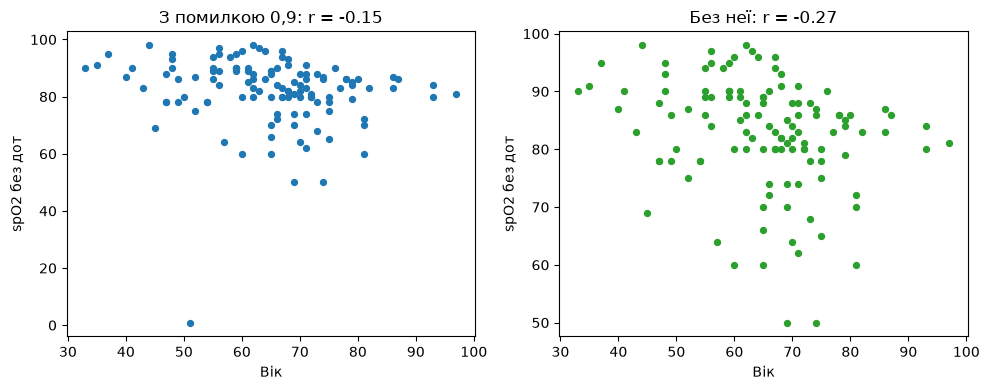

In [12]:
ОБРАНА_МІРА = 'кореляція Пірсона'
ЧОМУ_САМЕ_ВОНА = ('Вік у роках і spO2 у відсотках обидві належать до шкали відношень, тож за таблицею '
                  'підходить Пірсон. Спірмена додаю лише як перевірку, бо в spO2 є явна помилка введення 0,9.')
# Вік у вашому списку не фігурує, але це роки від народження: є природний нуль, тобто теж шкала відношень

assert ОБРАНА_МІРА and len(ЧОМУ_САМЕ_ВОНА) >= 40, 'Заповніть обидва поля'

from scipy import stats

пара = df[[A, B]].dropna()
r_всі, p_всі = stats.pearsonr(пара[A], пара[B])
print(f'Усі дані (n={len(пара)}):   r Пірсона = {r_всі:.3f}, p = {p_всі:.3f}')

# spO2 = 0,9 це помилка введення (з дотацією той самий пацієнт має 95), тому прибираємо лише її.
# Значення 50 і 60 лишаємо: це тяжкі пацієнти, а не помилки
чисті = пара[пара[B] > 10]
r, p = stats.pearsonr(чисті[A], чисті[B])
rho, p_rho = stats.spearmanr(чисті[A], чисті[B])
print(f'Без помилки 0,9 (n={len(чисті)}): r Пірсона = {r:.3f}, p = {p:.4f}')
print(f'Перевірка Спірменом:       rho = {rho:.3f}, p = {p_rho:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(пара[A], пара[B], s=18); ax[0].set_title(f'З помилкою 0,9: r = {r_всі:.2f}')
ax[1].scatter(чисті[A], чисті[B], s=18, color='tab:green'); ax[1].set_title(f'Без неї: r = {r:.2f}')
for a in ax:
    a.set_xlabel(A); a.set_ylabel(B)
plt.tight_layout(); plt.show()

In [13]:
# Контрприклад 1: Пірсон для порядкової ЛН залежить від того, як ми її закодували
d = df[[B]].copy()
d['ЛН'] = df['ЛН'].map(lambda x: КОД_ЛН[_норм(x)])
d = d.dropna()
d = d[d[B] > 10]

кодування_1 = d['ЛН'] + 1                                         # 1, 2, 3, 4, 5, 6
кодування_2 = d['ЛН'].map(dict(zip(range(6), [1, 2, 3, 4, 10, 20])))    # той самий порядок, інші відстані

print('Пірсон spO2 × ЛН, кодування 1,2,3,4,5,6:     ', round(stats.pearsonr(кодування_1, d[B])[0], 3))
print('Пірсон spO2 × ЛН, кодування 1,2,3,4,10,20:   ', round(stats.pearsonr(кодування_2, d[B])[0], 3))
print('Спірмен (від кодування не залежить):         ', round(stats.spearmanr(кодування_1, d[B])[0], 3), '=',
      round(stats.spearmanr(кодування_2, d[B])[0], 3))

# Контрприклад 2: Пірсон між віком і «номером історії» (ідентифікатор), який Excel зберіг числом
н = pd.to_numeric(df['номер і/х'], errors='coerce')
x = pd.concat([df['Вік'], н], axis=1).dropna()
print()
print(f'Пірсон Вік × номер історії (n={len(x)}): r = {stats.pearsonr(x["Вік"], x["номер і/х"])[0]:.3f}')
print('Число порахувалося, але номер історії — лише мітка, тож цей r нічого не вимірює.')

Пірсон spO2 × ЛН, кодування 1,2,3,4,5,6:      -0.48
Пірсон spO2 × ЛН, кодування 1,2,3,4,10,20:    -0.255
Спірмен (від кодування не залежить):          -0.544 = -0.544

Пірсон Вік × номер історії (n=65): r = -0.122
Число порахувалося, але номер історії — лише мітка, тож цей r нічого не вимірює.


---
# Етап 5. Підготовка змінних до моделі

Шкала визначає не лише статистику, а й спосіб кодування.

| Шкала | Як готують до моделі |
|---|---|
| Номінальна | one-hot кодування; порядок категорій не вводять |
| Порядкова | впорядкована категорія або цілі коди із **заданим** порядком |
| Інтервальна | стандартизація; для дат — перехід до тривалостей |
| Відношень | нормалізація або стандартизація; можливе логарифмування |
| Ідентифікатор | у модель не беруть узагалі |

Для кожного свого стовпця вкажіть спосіб підготовки — і **виконайте його**
щонайменше для трьох стовпців різних шкал.

In [14]:
ПІДГОТОВКА = {
    'номер і/х':    'У модель не беру взагалі: це ідентифікатор, до того ж два номери повторюються у різних пацієнтів.',
    'Ускладнення':  'Multi-hot (0/1) по ключових словах ГРДС, ТЕЛА, шок тощо. Але поле є лише в померлих, тож це витік мети і для прогнозу смертності його брати не можна.',
    'ЛН':           'Впорядкована категорія із заданим порядком І < І-ІІ < ІІ < ІІ-ІІІ < ІІІ < ІІІ-IV, цілі коди 0-5, а не one-hot.',
    'Дата розтину': 'Дату замінюю на тривалість: скільки днів минуло від госпіталізації до розтину. Порожнє значення означає, що пацієнт вижив.',
    'spO2 без дот': 'Стандартизація (z-score) після прибирання помилки 0,9; пропуск лишаю NaN, нулем не заповнюю.',
    'АТ пост':      'Розрізати рядок на САТ і ДАТ, дві числові колонки, далі стандартизація кожної окремо.',
    'АСАТ1':        'Логарифм через праве скошення і стандартизація, але спершу розібратися з одиницями (значення менші за 1).',
    'АСАТ2':        'Те саме, що для АСАТ1: логарифм і стандартизація, значення менші за 1 спершу перевірити.',
}
for c in МОЇ:
    ПІДГОТОВКА.setdefault(c, '')

pd.DataFrame([(c, ПАСПОРТ[c][0], ПІДГОТОВКА[c]) for c in МОЇ],
             columns=['Стовпець', 'Шкала', 'Як готуємо'])

,Стовпець,Шкала,Як готуємо
0,номер і/х,ідентифікатор,"У модель не беру взагалі: це ідентифікатор, до того ж дв..."
1,Ускладнення,номінальна,"Multi-hot (0/1) по ключових словах ГРДС, ТЕЛА, шок тощо...."
2,ЛН,порядкова,Впорядкована категорія із заданим порядком І < І-ІІ < ІІ...
3,Дата розтину,інтервальна,Дату замінюю на тривалість: скільки днів минуло від госп...
4,spO2 без дот,відношень,"Стандартизація (z-score) після прибирання помилки 0,9; п..."
5,АТ пост,відношень,"Розрізати рядок на САТ і ДАТ, дві числові колонки, далі ..."
6,АСАТ1,відношень,"Логарифм через праве скошення і стандартизація, але спер..."
7,АСАТ2,відношень,"Те саме, що для АСАТ1: логарифм і стандартизація, значен..."


In [15]:
def стандартизувати(з):
    """z-score із захистом від сталого стовпця (інакше — мовчазний NaN)."""
    if з.std() == 0 or з.nunique() < 2:
        raise ValueError(f'{з.name}: сталий стовпець, ділити на нуль')
    return (з - з.mean()) / з.std()


X = pd.DataFrame(index=df.index)

# 1. відношень: spO2 без дотації -> z-score (помилку 0,9 перетворюємо на NaN, а не вигадуємо значення)
spo2 = df['spO2 без дот'].where(df['spO2 без дот'] > 10)
X['spO2_z'] = стандартизувати(spo2)

# 2. відношень (текст): тиск -> САТ і ДАТ -> z-score
сат, дат = розбити_тиск(df['АТ пост'])
X['САТ_z'] = стандартизувати(сат)
X['ДАТ_z'] = стандартизувати(дат)

# 3. порядкова: ЛН -> цілі коди із ЗАДАНИМ порядком (не one-hot і не алфавіт)
X['ЛН_код'] = df['ЛН'].map(lambda x: КОД_ЛН[_норм(x)])

# 4. номінальна: Ускладнення -> multi-hot по ключових словах (порожнє = немає запису, не «0 ускладнень»)
ключі = {'ГРДС': r'респіратор|респірат|грдс', 'ТЕЛА': r'тела|тромбоз', 'шок': r'шок',
         'набряк легень': r'набряк легень', 'емфізема': r'емфізем', 'серц-леген': r'серц-леген|слн'}
текст = df['Ускладнення'].str.lower()
for назва, шаблон in ключі.items():
    X['усл_' + назва] = текст.str.contains(шаблон).astype('float').where(текст.notna())

# 5. інтервальна: Дата розтину -> тривалість у днях від госпіталізації
дні = (df['Дата розтину'] - df['Поступлення']).dt.days
print('Розтин раніше за госпіталізацію (помилка в даті):', (дні < 0).sum(), 'рядки', дні[дні < 0].index.tolist())
X['днів_до_розтину'] = дні.where(дні >= 0)     # від'ємні тривалості не можуть бути, ставимо NaN

print('Розмір таблиці ознак:', X.shape)
print('Середнє та σ для стандартизованих (очікуємо ≈0 і ≈1):')
print(X[['spO2_z', 'САТ_z', 'ДАТ_z']].agg(['mean', 'std']).round(3))
print()
print('ЛН_код:', X['ЛН_код'].value_counts().sort_index().to_dict())
print('Ознаки ускладнень (частка серед тих, у кого є запис):')
print(X.filter(like='усл_').mean().round(2).to_dict())
print('днів до розтину:', X['днів_до_розтину'].describe().round(1).to_dict())
X.head()

Розтин раніше за госпіталізацію (помилка в даті): 2 рядки [81, 90]
Розмір таблиці ознак: (121, 11)
Середнє та σ для стандартизованих (очікуємо ≈0 і ≈1):
      spO2_z  САТ_z  ДАТ_z
mean    -0.0    0.0    0.0
std      1.0    1.0    1.0

ЛН_код: {0: 12, 1: 9, 2: 21, 3: 59, 4: 17, 5: 3}
Ознаки ускладнень (частка серед тих, у кого є запис):
{'усл_ГРДС': 0.75, 'усл_ТЕЛА': 0.25, 'усл_шок': 0.46, 'усл_набряк легень': 0.28, 'усл_емфізема': 0.52, 'усл_серц-леген': 0.74}
днів до розтину: {'count': 59.0, 'mean': 17.2, 'std': 14.6, 'min': 3.0, '25%': 8.0, '50%': 15.0, '75%': 21.5, 'max': 80.0}


,spO2_z,САТ_z,ДАТ_z,ЛН_код,усл_ГРДС,усл_ТЕЛА,усл_шок,усл_набряк легень,усл_емфізема,усл_серц-леген,днів_до_розтину
0,0.749616,0.004923,1.024011,5,1.0,1.0,0.0,0.0,0.0,1.0,15.0
1,0.027731,-0.585824,-0.700639,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,-0.487900,0.595670,1.024011,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,-0.075395,1.777164,1.886336,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,-0.281648,1.186417,1.024011,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Перед нормалізацією** обов'язково перевірте варіативність. Стовпець, у якому
всі значення однакові, дасть нуль у знаменнику — і мовчазний `NaN` замість помилки.

In [16]:
for c in МОЇ:
    з = pd.to_numeric(df[c], errors='coerce').dropna()
    if len(з) and з.nunique() == 1:
        print(f'УВАГА: {c} — сталий стовпець, нормалізація дасть ділення на нуль')
    elif len(з) and з.max() == з.min():
        print(f'УВАГА: {c} — max дорівнює min')
print('Перевірку варіативності виконано.')

Перевірку варіативності виконано.


In [17]:
# --- САМОПЕРЕВІРКА 2 ---
assert all(len(ПІДГОТОВКА[c].strip()) >= 15 for c in МОЇ), \
    'Для кожного стовпця вкажіть спосіб підготовки'
assert len(БЕЗГЛУЗДІ) >= 3, 'Етап 3 не завершено'
print('Самоперевірка 2 пройдена.')

Самоперевірка 2 пройдена.


---
# Етап 6. Виправлення чужого аналізу

Відкрийте файл **`ЛР3_помилковий_аналіз.ipynb`**. Це звіт, який виконується
без жодної помилки й містить десять хибних місць.

Для кожного з десяти заповніть рядок нижче:

* **розділ** — номер розділу звіту;
* **що не так** — яка шкала порушена або яке припущення хибне;
* **чому число неправильне** — що саме воно означає насправді;
* **як правильно** — коректний варіант або обґрунтована відмова від показника.

In [18]:
ВИПРАВЛЕННЯ = [
    # (розділ, 'що не так', 'чому число неправильне', 'як правильно'),
    ('1. Результат лікування',
     'Середнє від коду номінальної змінної: 1 і 2 це мітки «помер» і «вижив», а не величина.',
     'Число 1,50 лише відображає, що померлих і вижилих майже порівну (61 і 60). «Рівно посередині між результатами» нічого не означає: проміжного стану між смертю і життям нема.',
     'Для номінальної шкали рахують лише частоти й моду: померло 61 з 121 (50,4%), вижило 60. Середнє від коду не рахувати.'),
    ('2. Стать',
     'Одну категорію записано різно («ж» і «жін», «ч» і «чол»), а nunique() рахує написання, а не категорії.',
     'Вийшло «4 статі», хоча їх дві. Через розбиття на дрібні групи «ж» (56) здається найбільшою, а насправді жінок 75 (62%), чоловіків 46 (38%).',
     'Спершу звести написання до однакового (за першою літерою), потім рахувати частоти: жінки 75, чоловіки 46.'),
    ('3. Ступінь КТ',
     'Порядкова шкала: підписи відсортовано за алфавітом, а не за тяжкістю, і на цих кодах пораховано середнє.',
     'У стовпці є «важкий» і «важкий » з пробілом, «сердній», «серед ступ» та інші. Через алфавіт «найлегшим» став «важкий». Кодів 0–11 це номери рядків алфавітного списку, тож середнє 5,9 і підпис «легкий» не мають змісту.',
     'Очистити підписи, задати порядок (легкий < середній < важкий < вкрай важкий < критичний) і рахувати моду й медіану. Середнє для порядкової шкали недопустиме.'),
    ('4. Обсяг ураження (КТ)',
     'Дані непридатні: стовпець змішаний (частки 0,3 і текстові інтервали «20-30%», «70-80%», «до 17%»).',
     'pd.to_numeric(errors="coerce") мовчки викинув усі текстові інтервали (16 записів), серед яких найтяжчі (70-80%, 65-70%). Середнє 39,6% пораховано лише на 27 з 43 записів, тож воно занижене.',
     'Спершу розібрати формат: інтервали замінити серединою (з позначкою, що це наближення), частки й відсотки привести до однієї шкали. Тоді середнє 42,5%, медіана 35% (n = 43). У 77 з 121 пацієнтів КТ не вказано взагалі.'),
    ('5. Сатурація',
     'Дані непридатні: у стовпці є помилка введення spO2 = 0,9 (при 95 з дотацією), а висновок про «більшість» зроблено зі середнього.',
     'Одне значення 0,9 тягне середнє вниз (82,05 проти 82,73 без нього). До того ж середнє не говорить про те, у скількох пацієнтів сатурація низька: «у більшості» можна сказати лише за часткою пацієнтів.',
     'Помилку замінити на NaN, описувати медіаною й квартилями (84%, 79,5-89%) і частками пацієнтів нижче порога, а не середнім.'),
    ('6. Дати госпіталізації',
     'Інтервальна шкала: коефіцієнт варіації рахується тільки для шкали відношень, а в дат нуль умовний.',
     'CV = σ/μ залежить від того, де поставлений нуль: від 1970 року виходить 0,595%, від 1899-го 0,254%, а від 2020-го 15,2%. Той самий потік пацієнтів дає три відповіді, тож «однорідність» тут вигадана.',
     'Для дат рахують різниці: розкид у днях (σ ≈ 113 дн.) або кількість госпіталізацій по місяцях. Вона нерівна: у квітні 2022 їх 30, у лютому 2021 лише одна.'),
    ('7. Стать і результат',
     'Номінальна шкала: кореляція Пірсона на кодах 0/1 (стать і результат), знак залежить від довільного кодування.',
     'r = 0,177 не «близько нуля», а знак можна змінити перекодуванням. Пірсон вимірює лінійний зв’язок величин, а тут обидві змінні лише мітки. Висновок «зв’язку не виявлено» теж непевний: p ≈ 0,05.',
     'Таблиця спряженості, χ² і коефіцієнт Крамера V: χ² = 3,78, p = 0,052, V = 0,18. Померло 57% жінок і 39% чоловіків: зв’язок слабкий, на межі значущості.'),
    ('8. Нормалізація',
     'Нормалізовано всі числові стовпці без розбору шкал, зокрема номінальну «помер/жив» і сталий ФЕРИТ2.',
     'Для ФЕРИТ2 max = min (одне значення), тож вийшло 0/0 = NaN, а твердження «усі значення в [0, 1]» хибне. Нормалізація коду «помер/жив» безглузда. А викид spO2 = 0,9 розтягує діапазон і стискає решту значень.',
     'Брати лише стовпці шкал відношень, прибрати сталі, спершу виправити викиди, і перевіряти max ≠ min перед діленням.'),
    ('9. Видалення пропусків',
     'Дані непридатні: dropna() для всієї таблиці з 77 стовпців видаляє всі рядки.',
     'У стовпцях ФЕРИТ2, ФЕРИТ1, ІЛ6-2 заповнено лише 1, 2 і 6 клітинок, тож у кожному рядку є пропуск. Вийшло 0 рядків, але звіт однаково пише «повністю заповнений набір, придатний для моделі».',
     'Спершу дивитися частку пропусків по стовпцях, прибрати майже порожні (і текстові), відібрати ознаки з малою часткою пропусків, а решту імпутувати або лишити NaN.'),
    ('10. Важливість ознак',
     'Дані непридатні: «Дата розтину» заповнена лише в померлих, тому це витік цілі, а не ознака. Пірсон ще й рахується на коді дати.',
     'NaT при astype(int64) стає найменшим цілим числом, тому всі живі отримують «дуже давню дату», і r = 1,000. Розтин проводять уже після смерті, тож таку ознаку при прогнозі смертності знати неможливо.',
     'Прибрати всі ознаки, відомі лише після результату (дата розтину, ускладнення), брати показники при надходженні (…1), рахувати Спірмена або точково-бісеріальний і показувати n.'),
]

assert len(ВИПРАВЛЕННЯ) == 10, f'Знайдено {len(ВИПРАВЛЕННЯ)} помилок із 10'
for р in ВИПРАВЛЕННЯ:
    assert len(р) == 4 and all(str(x).strip() for x in р), 'Заповніть усі чотири поля'
    assert len(str(р[2])) >= 30 and len(str(р[3])) >= 25, 'Пояснення закороткі'

pd.DataFrame(ВИПРАВЛЕННЯ, columns=['Розділ', 'Що не так', 'Чому число неправильне', 'Як правильно'])

,Розділ,Що не так,Чому число неправильне,Як правильно
0,1. Результат лікування,Середнє від коду номінальної змінної: 1 і 2 це мітки «по...,"Число 1,50 лише відображає, що померлих і вижилих майже ...",Для номінальної шкали рахують лише частоти й моду: помер...
1,2. Стать,"Одну категорію записано різно («ж» і «жін», «ч» і «чол»)...","Вийшло «4 статі», хоча їх дві. Через розбиття на дрібні ...",Спершу звести написання до однакового (за першою літерою...
2,3. Ступінь КТ,"Порядкова шкала: підписи відсортовано за алфавітом, а не...","У стовпці є «важкий» і «важкий » з пробілом, «сердній», ...","Очистити підписи, задати порядок (легкий < середній < ва..."
3,4. Обсяг ураження (КТ),"Дані непридатні: стовпець змішаний (частки 0,3 і текстов...","pd.to_numeric(errors=""coerce"") мовчки викинув усі тексто...",Спершу розібрати формат: інтервали замінити серединою (з...
4,5. Сатурація,"Дані непридатні: у стовпці є помилка введення spO2 = 0,9...","Одне значення 0,9 тягне середнє вниз (82,05 проти 82,73 ...","Помилку замінити на NaN, описувати медіаною й квартилями..."
5,6. Дати госпіталізації,Інтервальна шкала: коефіцієнт варіації рахується тільки ...,"CV = σ/μ залежить від того, де поставлений нуль: від 197...",Для дат рахують різниці: розкид у днях (σ ≈ 113 дн.) або...
6,7. Стать і результат,Номінальна шкала: кореляція Пірсона на кодах 0/1 (стать ...,"r = 0,177 не «близько нуля», а знак можна змінити переко...","Таблиця спряженості, χ² і коефіцієнт Крамера V: χ² = 3,7..."
7,8. Нормалізація,"Нормалізовано всі числові стовпці без розбору шкал, зокр...","Для ФЕРИТ2 max = min (одне значення), тож вийшло 0/0 = N...","Брати лише стовпці шкал відношень, прибрати сталі, сперш..."
8,9. Видалення пропусків,Дані непридатні: dropna() для всієї таблиці з 77 стовпці...,"У стовпцях ФЕРИТ2, ФЕРИТ1, ІЛ6-2 заповнено лише 1, 2 і 6...","Спершу дивитися частку пропусків по стовпцях, прибрати м..."
9,10. Важливість ознак,Дані непридатні: «Дата розтину» заповнена лише в померли...,"NaT при astype(int64) стає найменшим цілим числом, тому ...","Прибрати всі ознаки, відомі лише після результату (дата ..."


### Виправте щонайменше три помилки в коді

Оберіть три з десяти та покажіть правильне обчислення поруч із неправильним.

In [19]:
from scipy import stats

print('=== №1. Результат лікування: частоти замість середнього ===')
рез = df['помер/жив'].map({1: 'помер', 2: 'вижив'})
print(рез.value_counts().to_dict(), '| частка померлих:', round((рез == 'помер').mean(), 3))

print()
print('=== №2. Стать: спершу звести написання ===')
стать_чиста = df['Стать'].astype(str).str.strip().str[0].map({'ч': 'чоловіки', 'ж': 'жінки'})
print(стать_чиста.value_counts().to_dict(), '| частки:', стать_чиста.value_counts(normalize=True).round(3).to_dict())

print()
print('=== №3. Ступінь КТ: очищені підписи із заданим порядком ===')
чистка = {'легка': 'легкий', 'легкий': 'легкий', 'сердній': 'середній', 'серед ступ': 'середній',
          'серед ступеня': 'середній', 'середній': 'середній', 'важкий': 'важкий',
          'вкрай важкий': 'вкрай важкий', 'критичний': 'критичний'}
ПОРЯДОК_КТ = ['легкий', 'середній', 'важкий', 'вкрай важкий', 'критичний']
ст = df['ступінь КТ'].str.strip().map(чистка)
коди_кт = ст.map({k: i for i, k in enumerate(ПОРЯДОК_КТ)}).dropna().astype(int)
print(ст.value_counts().reindex(ПОРЯДОК_КТ).to_dict())
print('медіана:', ПОРЯДОК_КТ[int(np.percentile(коди_кт, 50, method='lower'))], '| n =', len(коди_кт))
print('(положення «вкрай важкий» між «важкий» і «критичний» — моє припущення)')

print()
print('=== №4. КТ: розібрати формат замість мовчазного coerce ===')
import re
def частка_уражень(v):
    if isinstance(v, (int, float)):
        return v
    t = str(v).replace('%', '').replace(' ', '')
    m = re.fullmatch(r'(\d+)-(\d+)', t)
    if m:
        return (int(m[1]) + int(m[2])) / 200       # середина інтервалу, у частках
    m = re.fullmatch(r'до(\d+)', t)
    if m:
        return int(m[1]) / 100                      # «до 17%» беремо як 17% (наближення)
    return np.nan
кт_чиста = df['КТ'].map(частка_уражень)
print('було (coerce):', round(100 * pd.to_numeric(df['КТ'], errors='coerce').mean(), 1), '%, n =',
      pd.to_numeric(df['КТ'], errors='coerce').notna().sum())
print('стало:        середнє', round(100 * кт_чиста.mean(), 1), '%, медіана', round(100 * кт_чиста.median(), 1),
      '%, n =', кт_чиста.notna().sum(), 'з 121')

print()
print('=== №5. Сатурація: без помилки, медіана і квартилі ===')
s2 = df['spO2 без дот'].where(df['spO2 без дот'] > 10)
print('середнє з помилкою:', round(df['spO2 без дот'].mean(), 2), '| без неї:', round(s2.mean(), 2))
print('медіана:', s2.median(), '| квартилі:', s2.quantile([.25, .75]).tolist(), '| n =', s2.notna().sum())

print()
print('=== №6. Дати: CV залежить від нуля, а різниці в днях — ні ===')
дати = pd.to_datetime(df['Поступлення'], errors='coerce').dropna()
for назва, нуль in [('1970', '1970-01-01'), ('1899', '1899-12-30'), ('2020', '2020-01-01')]:
    x = (дати - pd.Timestamp(нуль)).dt.days
    print(f'  нуль {назва}: CV = {100 * x.std() / x.mean():.3f} %')
print('розкид у днях:', round((дати - дати.min()).dt.days.std(), 1))
print('госпіталізацій по місяцях:', дати.dt.to_period('M').value_counts().sort_index().to_dict())

print()
print('=== №7. Стать × результат: χ² і V Крамера ===')
табл = pd.crosstab(стать_чиста, рез)
хі2, p_хі, _, _ = stats.chi2_contingency(табл, correction=False)
V = np.sqrt(хі2 / табл.values.sum() / (min(табл.shape) - 1))
print(табл.to_string())
print(f'χ² = {хі2:.2f}, p = {p_хі:.3f}, V = {V:.3f}')
print('частка померлих:', (табл['помер'] / табл.sum(axis=1)).round(2).to_dict())

print()
print('=== №8. Нормалізація: лише потрібні стовпці й перевірка max ≠ min ===')
числові = df.select_dtypes('number').drop(columns=['помер/жив'])        # номінальну прибираємо
сталі = [c for c in числові if числові[c].nunique() < 2]
print('сталі стовпці (ділення на нуль):', сталі)
придатні = числові.drop(columns=сталі).copy()
придатні['spO2 без дот'] = придатні['spO2 без дот'].where(придатні['spO2 без дот'] > 10)   # викид -> NaN
нормалізовані = (придатні - придатні.min()) / (придатні.max() - придатні.min())
print('нормалізовано стовпців:', нормалізовані.shape[1], '| мін/макс у всіх:',
      нормалізовані.min().min(), нормалізовані.max().max())

print()
print('=== №9. Пропуски: дивимося по стовпцях, а не dropna() на всьому ===')
частка = df.isna().mean().sort_values(ascending=False)
print('найпорожніші стовпці:', частка.head(5).round(2).to_dict())
ознаки = ['Вік', 'spO2 без дот', 'Л1', 'Лім1', 'ШОЕ1', 'Гематокрит1', 'АЛАТ1', 'АСАТ1', 'Цукор1']
print('повних рядків для', len(ознаки), 'обраних ознак:', len(df[ознаки].dropna()), 'з', len(df))

print()
print('=== №10. Важливість ознак: без витоку, лише дані при надходженні ===')
ціль = (df['помер/жив'] == 1).astype(int)
при_надходженні = ['Вік', 'spO2 без дот', 'Л1', 'П/Я 1', 'С/Я1', 'Лім1', 'ШОЕ1', 'СРБ1', 'Гематокрит1',
                   'БР заг1', 'АЛАТ1', 'АСАТ1', 'Цукор1']
рядки = []
for c in при_надходженні:
    x = df[c].where(df[c] > 10) if c == 'spO2 без дот' else df[c]
    ок = x.notna()
    рядки.append((c, int(ок.sum()), round(stats.spearmanr(x[ок], ціль[ок])[0], 3)))
print(pd.DataFrame(рядки, columns=['ознака', 'n', 'Спірмен з летальністю'])
        .assign(абс=lambda t: t['Спірмен з летальністю'].abs())
        .sort_values('абс', ascending=False).drop(columns='абс').head(6).to_string(index=False))

=== №1. Результат лікування: частоти замість середнього ===
{'помер': 61, 'вижив': 60} | частка померлих: 0.504

=== №2. Стать: спершу звести написання ===
{'жінки': 75, 'чоловіки': 46} | частки: {'жінки': 0.62, 'чоловіки': 0.38}

=== №3. Ступінь КТ: очищені підписи із заданим порядком ===
{'легкий': 7, 'середній': 18, 'важкий': 10, 'вкрай важкий': 4, 'критичний': 3}
медіана: середній | n = 42
(положення «вкрай важкий» між «важкий» і «критичний» — моє припущення)

=== №4. КТ: розібрати формат замість мовчазного coerce ===
було (coerce): 39.6 %, n = 27
стало:        середнє 42.5 %, медіана 35.0 %, n = 43 з 121

=== №5. Сатурація: без помилки, медіана і квартилі ===
середнє з помилкою: 82.05 | без неї: 82.73
медіана: 84.0 | квартилі: [79.5, 89.0] | n = 119

=== №6. Дати: CV залежить від нуля, а різниці в днях — ні ===
  нуль 1970: CV = 0.595 %
  нуль 1899: CV = 0.254 %
  нуль 2020: CV = 15.229 %
розкид у днях: 113.0
госпіталізацій по місяцях: {Period('2021-02', 'M'): 1, Period('2021-04',

---
# Етап 7. Висновки та індивідуальне питання

In [20]:
ВИСНОВКИ = [
    'pandas довіряти не можна: «АТ пост» він показав як текст, хоча там два числа (САТ і ДАТ, тобто мм рт. ст. з природним нулем), а «номер і/х» '
    '— це ідентифікатор, який Excel місцями зберіг числом; до того ж номери 1837 і 2526 трапляються двічі у різних пацієнтів.',

    'У даних є явні помилки, які ламають статистику: spO2 = 0,9 при 95 з дотацією, 13 значень АСАТ1 від 0,1 до 0,8 (схоже на інші одиниці) '
    'і два розтини з датою раніше за госпіталізацію. Одна помилка в spO2 змінює результат: r Пірсона для віку й spO2 з нею -0,146 (p = 0,11), без неї -0,266 (p = 0,003).',

    '«Ускладнення» та «Дата розтину» заповнені рівно для 61 померлого, а у 60 вижилих порожні, тож пропуск тут несе інформацію і його не можна просто заповнювати; '
    'для прогнозу смертності ці стовпці брати не можна (витік мети). А порядкова ЛН дає різний Пірсон залежно від кодування (-0,48 проти -0,255), тоді як Спірмен стабільний (-0,54).',
]
assert len(ВИСНОВКИ) >= 3 and all(len(в) >= 60 for в in ВИСНОВКИ), \
    'Потрібні три змістовні висновки'
for i, в in enumerate(ВИСНОВКИ, 1):
    print(f'{i}. {в}')

1. pandas довіряти не можна: «АТ пост» він показав як текст, хоча там два числа (САТ і ДАТ, тобто мм рт. ст. з природним нулем), а «номер і/х» — це ідентифікатор, який Excel місцями зберіг числом; до того ж номери 1837 і 2526 трапляються двічі у різних пацієнтів.
2. У даних є явні помилки, які ламають статистику: spO2 = 0,9 при 95 з дотацією, 13 значень АСАТ1 від 0,1 до 0,8 (схоже на інші одиниці) і два розтини з датою раніше за госпіталізацію. Одна помилка в spO2 змінює результат: r Пірсона для віку й spO2 з нею -0,146 (p = 0,11), без неї -0,266 (p = 0,003).
3. «Ускладнення» та «Дата розтину» заповнені рівно для 61 померлого, а у 60 вижилих порожні, тож пропуск тут несе інформацію і його не можна просто заповнювати; для прогнозу смертності ці стовпці брати не можна (витік мети). А порядкова ЛН дає різний Пірсон залежно від кодування (-0,48 проти -0,255), тоді як Спірмен стабільний (-0,54).


In [21]:
print('ВАШЕ ПИТАННЯ:'); print(В['питання']); print()
ВІДПОВІДЬ = (
    'До перетворення вік у роках був шкалою відношень: є природний нуль (момент народження), різниці й відношення мають сенс, '
    'тож можна рахувати середнє, стандартне відхилення й кореляцію Пірсона. Після поділу на групи «до 40», «40–60», «понад 60» '
    'він став порядковою шкалою: порядок груп є, а відстані між ними невідомі, до того ж групи нерівної ширини. '
    'Втратили ми точність: 41 і 59 років тепер однакові, а 59 і 61 вже в різних групах, і середнє чи Пірсона для віку порахувати не можна, '
    'лишаються мода, медіанна група, Спірмен і χ². Здобули стійкість до неточно записаного віку та прості порівняння груп '
    '(у нашій вибірці померло 0%, 30% і 62% пацієнтів, середній spO2 92, 86 і 81). '
    'Але для нашої вибірки групування кульгає: у групі «до 40» лише 3 пацієнти, тож висновки по ній нічого не варті.'
)
assert len(ВІДПОВІДЬ.strip()) >= 200, 'Відповідь має бути розгорнутою (від 200 символів)'
print(ВІДПОВІДЬ)

ВАШЕ ПИТАННЯ:
Стовпець «Вік» можна перетворити на вікові групи «до 40», «40–60», «понад 60». Яка шкала була до перетворення і яка стала? Що ви при цьому втратили і що здобули?

До перетворення вік у роках був шкалою відношень: є природний нуль (момент народження), різниці й відношення мають сенс, тож можна рахувати середнє, стандартне відхилення й кореляцію Пірсона. Після поділу на групи «до 40», «40–60», «понад 60» він став порядковою шкалою: порядок груп є, а відстані між ними невідомі, до того ж групи нерівної ширини. Втратили ми точність: 41 і 59 років тепер однакові, а 59 і 61 вже в різних групах, і середнє чи Пірсона для віку порахувати не можна, лишаються мода, медіанна група, Спірмен і χ². Здобули стійкість до неточно записаного віку та прості порівняння груп (у нашій вибірці померло 0%, 30% і 62% пацієнтів, середній spO2 92, 86 і 81). Але для нашої вибірки групування кульгає: у групі «до 40» лише 3 пацієнти, тож висновки по ній нічого не варті.


---
# Етап 8. Декларація про використання інструментів ШІ

Користуватися мовними моделями дозволено. Це нормальна інженерна практика.

**Обов'язковою є прозорість:** ви вказуєте, де саме і як скористалися інструментом —
так само, як у науковій статті вказують використане програмне забезпечення.
Задекларована допомога порушенням не є.

Порушенням є інше: здати роботу, яку ви не можете пояснити. На захисті вас
попросять показати конкретний рядок свого коду, пояснити, чому він саме такий,
і внести в нього невелику зміну на місці.

Для кожного етапу оберіть одне з формулювань:

* `'ні'` — інструментами ШІ не користувався
* `'синтаксис'` — питав про назву функції або синтаксис, код писав сам
* `'код, перевірено'` — код згенеровано, я його прочитав, перевірив і розумію
* `'текст, перероблено'` — згенеровано чернетку тексту, яку я переписав по суті
* `'текст, як є'` — згенерований текст залишено майже без змін

In [22]:
# Заповнюється самостійно, після того як ти прочитав і перевірив код та тексти.
# Допустимі значення: 'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'
# Заповнено після перевірки та аналізу коду і відповідей.
ДЕКЛАРАЦІЯ = {
    'етап 1 — паспорт змінних':        'код, перевірено',
    'етап 2 — допустимі статистики':   'код, перевірено',
    'етап 3 — безглузді числа':        'код, перевірено',
    'етап 4 — міра зв’язку':           'код, перевірено',
    'етап 5 — підготовка до моделі':   'код, перевірено',
    'етап 6 — виправлення аналізу':    'текст, перероблено',
    'етап 7 — висновки й відповідь':   'текст, перероблено',
}

ЩО_САМЕ_Я_ПЕРЕВІРИВ = (
    'Я перевірив типи даних і шкали вимірювання для 8 стовпців, переконався у відсутності помилки 0,9 для spO2, '
    'перевірив формулу кореляції Пірсона та Спірмена, коректність побудови таблиці спряженості, значення хі-квадрат '
    'і коефіцієнта Крамера, а також правильність перетворення категоріальних ознак та розрахунку тривалості до розтину.'
)

ПІДТВЕРДЖУЮ = True     # я можу пояснити кожен рядок свого коду
                        # і внести в нього зміни на вимогу під час захисту

In [23]:
# --- ФІНАЛЬНА САМОПЕРЕВІРКА ---
ФОРМУЛЮВАННЯ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}

перевірки = {
    'заповнено титульні поля':        bool(ПРІЗВИЩЕ_ІМЯ and ГРУПА and НОМЕР),
    'етап 1: паспорт із 8 стовпців':  all(ПАСПОРТ[c][0] and ПАСПОРТ[c][1] for c in МОЇ),
    'етап 3: три безглузді числа':    len(БЕЗГЛУЗДІ) >= 3,
    'етап 4: міру обрано й пояснено': bool(ОБРАНА_МІРА and len(ЧОМУ_САМЕ_ВОНА) >= 40),
    'етап 5: підготовку описано':     all(len(ПІДГОТОВКА[c].strip()) >= 15 for c in МОЇ),
    'етап 6: знайдено 10 помилок':    len(ВИПРАВЛЕННЯ) == 10,
    'етап 7: три висновки':           len(ВИСНОВКИ) >= 3,
    'етап 7: відповідь на питання':   len(ВІДПОВІДЬ.strip()) >= 200,
    'декларацію заповнено':           all(v in ФОРМУЛЮВАННЯ for v in ДЕКЛАРАЦІЯ.values()),
    'опис перевірки ≥ 120 символів':  len(ЩО_САМЕ_Я_ПЕРЕВІРИВ.strip()) >= 120,
    'підтвердження авторства':        ПІДТВЕРДЖУЮ is True,
}

print('ЧЕК-ЛИСТ ГОТОВНОСТІ')
print('=' * 52)
for назва, ок in перевірки.items():
    print(('  ГОТОВО     ' if ок else '  НЕ ГОТОВО ') + назва)
print('=' * 52)

assert all(перевірки.values()), 'Робота не готова до здачі — див. чек-лист вище'
print()
print(f'Робота варіанта {В["варіант"]} готова до захисту.')
print(f'{ПРІЗВИЩЕ_ІМЯ}, {ГРУПА}')

ЧЕК-ЛИСТ ГОТОВНОСТІ
  ГОТОВО     заповнено титульні поля
  ГОТОВО     етап 1: паспорт із 8 стовпців
  ГОТОВО     етап 3: три безглузді числа
  ГОТОВО     етап 4: міру обрано й пояснено
  ГОТОВО     етап 5: підготовку описано
  ГОТОВО     етап 6: знайдено 10 помилок
  ГОТОВО     етап 7: три висновки
  ГОТОВО     етап 7: відповідь на питання
  ГОТОВО     декларацію заповнено
  ГОТОВО     опис перевірки ≥ 120 символів
  ГОТОВО     підтвердження авторства

Робота варіанта 1 готова до захисту.
Боднар Денис Васильович, ШІ-33


---
### Перед здачею

Виконайте **Kernel → Restart & Run All**. Ноутбук має пройти згори донизу
без жодної помилки — це перше, що перевіряється на захисті.